# Student Habits and Academic Performance Analysis
  

## Objective
- The objective of this project is to analyze how different student habits such as study hours, sleep, attendance, social media usage, and tutoring affect exam scores.

## Business Understanding

- Educational institutions want to understand which student habits and academic factors are associated with examination performance. This analysis examines study hours, attendance, sleep, stress, motivation, tutoring, previous GPA, and other factors to identify patterns related to student academic performance.

### APPASA framework


1. Ask
- What factors are associated with student exam performance?

2. Prepare
- Load and inspect the student habits dataset.

3. Process
- Clean missing values, check duplicates, verify data types,
and create useful derived variables.

4. Analyze
- Analyze relationships between habits and exam scores.

5. Share
- Present findings using charts and summary tables.

6. Act
- Provide practical recommendations based on the findings.

## Dataset Description
- This dataset contains information about students' daily habits and academic performance.

## Questions to Explore
1. Does studying more improve exam scores?
2. Does sleep affect performance?
3. Does tutoring help students?
4. Does attendance influence marks?
5. Does social media usage affect exam scores?

## Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Load Dataset
- What does the dataset look like?

In [2]:
df=pd.read_csv("enhanced_student_habits_performance_dataset.csv")

In [3]:
df

,student_id,age,gender,major,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,...,screen_time,study_environment,access_to_tutoring,family_income_range,parental_support_level,motivation_level,exam_anxiety_score,learning_style,time_management_score,exam_score
0,100000,26,Male,Computer Science,7.645367,3.0,0.1,Yes,70.3,6.2,...,10.9,Co-Learning Group,Yes,High,9,7,8,Reading,3.0,100
1,100001,28,Male,Arts,5.700000,0.5,0.4,No,88.4,7.2,...,8.3,Co-Learning Group,Yes,Low,7,2,10,Reading,6.0,99
2,100002,17,Male,Arts,2.400000,4.2,0.7,No,82.1,9.2,...,8.0,Library,Yes,High,3,9,6,Kinesthetic,7.6,98
3,100003,27,Other,Psychology,3.400000,4.6,2.3,Yes,79.3,4.2,...,11.7,Co-Learning Group,Yes,Low,5,3,10,Reading,3.2,100
4,100004,25,Female,Business,4.700000,0.8,2.7,Yes,62.9,6.5,...,9.4,Quiet Room,Yes,Medium,9,1,10,Reading,7.1,98
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79995,179995,16,Male,Engineering,3.700000,2.1,1.0,Yes,80.8,6.1,...,8.3,Library,No,Low,1,4,10,Auditory,5.3,88
79996,179996,16,Female,Business,1.200000,0.4,2.9,No,99.5,4.1,...,4.7,Co-Learning Group,No,Low,3,2,10,Kinesthetic,6.8,52
79997,179997,26,Female,Arts,4.100000,1.6,1.6,Yes,46.1,8.3,...,7.5,Dorm,No,Medium,7,1,10,Visual,1.3,89
79998,179998,23,Other,Biology,3.800000,0.6,3.5,Yes,58.7,5.8,...,9.3,Quiet Room,Yes,Low,2,8,7,Kinesthetic,3.7,96


In [4]:
df.head()

,student_id,age,gender,major,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,...,screen_time,study_environment,access_to_tutoring,family_income_range,parental_support_level,motivation_level,exam_anxiety_score,learning_style,time_management_score,exam_score
0,100000,26,Male,Computer Science,7.645367,3.0,0.1,Yes,70.3,6.2,...,10.9,Co-Learning Group,Yes,High,9,7,8,Reading,3.0,100
1,100001,28,Male,Arts,5.700000,0.5,0.4,No,88.4,7.2,...,8.3,Co-Learning Group,Yes,Low,7,2,10,Reading,6.0,99
2,100002,17,Male,Arts,2.400000,4.2,0.7,No,82.1,9.2,...,8.0,Library,Yes,High,3,9,6,Kinesthetic,7.6,98
3,100003,27,Other,Psychology,3.400000,4.6,2.3,Yes,79.3,4.2,...,11.7,Co-Learning Group,Yes,Low,5,3,10,Reading,3.2,100
4,100004,25,Female,Business,4.700000,0.8,2.7,Yes,62.9,6.5,...,9.4,Quiet Room,Yes,Medium,9,1,10,Reading,7.1,98


## Dataset Overview

- The dataset contains information about student habits and their exam performance. Each row represents one student and each column represents a specific characteristic or habit.

In [5]:
df.tail()

,student_id,age,gender,major,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,...,screen_time,study_environment,access_to_tutoring,family_income_range,parental_support_level,motivation_level,exam_anxiety_score,learning_style,time_management_score,exam_score
79995,179995,16,Male,Engineering,3.7,2.1,1.0,Yes,80.8,6.1,...,8.3,Library,No,Low,1,4,10,Auditory,5.3,88
79996,179996,16,Female,Business,1.2,0.4,2.9,No,99.5,4.1,...,4.7,Co-Learning Group,No,Low,3,2,10,Kinesthetic,6.8,52
79997,179997,26,Female,Arts,4.1,1.6,1.6,Yes,46.1,8.3,...,7.5,Dorm,No,Medium,7,1,10,Visual,1.3,89
79998,179998,23,Other,Biology,3.8,0.6,3.5,Yes,58.7,5.8,...,9.3,Quiet Room,Yes,Low,2,8,7,Kinesthetic,3.7,96
79999,179999,25,Other,Engineering,3.0,4.5,3.4,Yes,97.7,5.3,...,12.2,Co-Learning Group,Yes,Medium,1,8,7,Reading,6.7,100


In [6]:
df.shape

(80000, 31)

In [7]:
df.columns

Index(['student_id', 'age', 'gender', 'major', 'study_hours_per_day',
       'social_media_hours', 'netflix_hours', 'part_time_job',
       'attendance_percentage', 'sleep_hours', 'diet_quality',
       'exercise_frequency', 'parental_education_level', 'internet_quality',
       'mental_health_rating', 'extracurricular_participation', 'previous_gpa',
       'semester', 'stress_level', 'dropout_risk', 'social_activity',
       'screen_time', 'study_environment', 'access_to_tutoring',
       'family_income_range', 'parental_support_level', 'motivation_level',
       'exam_anxiety_score', 'learning_style', 'time_management_score',
       'exam_score'],
      dtype='str')

## Data Understanding
- What is the structure of dataset?

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 80000 entries, 0 to 79999
Data columns (total 31 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   student_id                     80000 non-null  int64  
 1   age                            80000 non-null  int64  
 2   gender                         80000 non-null  str    
 3   major                          80000 non-null  str    
 4   study_hours_per_day            80000 non-null  float64
 5   social_media_hours             80000 non-null  float64
 6   netflix_hours                  80000 non-null  float64
 7   part_time_job                  80000 non-null  str    
 8   attendance_percentage          80000 non-null  float64
 9   sleep_hours                    80000 non-null  float64
 10  diet_quality                   80000 non-null  str    
 11  exercise_frequency             80000 non-null  int64  
 12  parental_education_level       80000 non-null  str    
 1

## Observation

- The info() function helps identify the number of rows, columns, data types, and missing values present in the dataset.

In [9]:
df.describe()

,student_id,age,study_hours_per_day,social_media_hours,netflix_hours,attendance_percentage,sleep_hours,exercise_frequency,mental_health_rating,previous_gpa,semester,stress_level,social_activity,screen_time,parental_support_level,motivation_level,exam_anxiety_score,time_management_score,exam_score
count,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000
mean,139999.500000,22.004288,4.174388,2.501366,1.997754,69.967884,7.017418,3.516587,6.804108,3.602448,4.497338,5.012478,2.500225,9.673029,5.479438,5.488525,8.508475,5.499132,89.141350
std,23094.155105,3.745570,2.004135,1.445441,1.155992,17.333015,1.467377,2.291575,1.921579,0.462876,2.295312,1.953174,1.704292,2.780869,2.873327,2.867782,1.796411,2.603534,11.591497
min,100000.000000,16.000000,0.000000,0.000000,0.000000,40.000000,4.000000,0.000000,1.000000,1.640000,1.000000,1.000000,0.000000,0.300000,1.000000,1.000000,5.000000,1.000000,36.000000
25%,119999.750000,19.000000,2.800000,1.200000,1.000000,55.000000,6.000000,2.000000,5.500000,3.270000,2.000000,3.600000,1.000000,7.800000,3.000000,3.000000,7.000000,3.200000,82.000000
50%,139999.500000,22.000000,4.125624,2.500000,2.000000,69.900000,7.000000,4.000000,6.900000,3.790000,5.000000,5.000000,2.000000,9.700000,5.000000,5.000000,10.000000,5.500000,93.000000
75%,159999.250000,25.000000,5.500000,3.800000,3.000000,84.900000,8.000000,6.000000,8.200000,4.000000,7.000000,6.400000,4.000000,11.600000,8.000000,8.000000,10.000000,7.800000,100.000000
max,179999.000000,28.000000,12.000000,5.000000,4.000000,100.000000,12.000000,7.000000,10.000000,4.000000,8.000000,10.000000,5.000000,21.000000,10.000000,10.000000,10.000000,10.000000,100.000000


## Observation

- The statistical summary provides information such as mean, minimum, maximum, and standard deviation of numerical columns. 
- This helps us understand the overall distribution of the data.

In [10]:
df.describe(include="object")

/tmp/ipykernel_114624/702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,gender,major,part_time_job,diet_quality,parental_education_level,internet_quality,extracurricular_participation,dropout_risk,study_environment,access_to_tutoring,family_income_range,learning_style
count,80000,80000,80000,80000,80000,80000,80000,80000,80000,80000,80000,80000
unique,3,6,2,3,5,3,2,2,5,2,3,4
top,Female,Arts,No,Good,Some College,High,No,No,Dorm,No,Low,Kinesthetic
freq,26705,13505,40195,39935,16115,26749,40058,78418,16119,40039,26720,20143


## Data Cleaning
- Are there missing values?

In [11]:
df.isnull()

,student_id,age,gender,major,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,...,screen_time,study_environment,access_to_tutoring,family_income_range,parental_support_level,motivation_level,exam_anxiety_score,learning_style,time_management_score,exam_score
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79995,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
79996,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
79997,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
79998,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [12]:
df.isna().sum()

student_id                       0
age                              0
gender                           0
major                            0
study_hours_per_day              0
social_media_hours               0
netflix_hours                    0
part_time_job                    0
attendance_percentage            0
sleep_hours                      0
diet_quality                     0
exercise_frequency               0
parental_education_level         0
internet_quality                 0
mental_health_rating             0
extracurricular_participation    0
previous_gpa                     0
semester                         0
stress_level                     0
dropout_risk                     0
social_activity                  0
screen_time                      0
study_environment                0
access_to_tutoring               0
family_income_range              0
parental_support_level           0
motivation_level                 0
exam_anxiety_score               0
learning_style      

Are there duplicate records?

## Observation

- The dataset contains very few or no missing values, making it suitable for analysis and visualization.

In [13]:
df.duplicated()

0        False
1        False
2        False
3        False
4        False
         ...  
79995    False
79996    False
79997    False
79998    False
79999    False
Length: 80000, dtype: bool

In [14]:
df.duplicated().sum()

np.int64(0)

### Data Processing/ Transformation

In [15]:
df

,student_id,age,gender,major,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,...,screen_time,study_environment,access_to_tutoring,family_income_range,parental_support_level,motivation_level,exam_anxiety_score,learning_style,time_management_score,exam_score
0,100000,26,Male,Computer Science,7.645367,3.0,0.1,Yes,70.3,6.2,...,10.9,Co-Learning Group,Yes,High,9,7,8,Reading,3.0,100
1,100001,28,Male,Arts,5.700000,0.5,0.4,No,88.4,7.2,...,8.3,Co-Learning Group,Yes,Low,7,2,10,Reading,6.0,99
2,100002,17,Male,Arts,2.400000,4.2,0.7,No,82.1,9.2,...,8.0,Library,Yes,High,3,9,6,Kinesthetic,7.6,98
3,100003,27,Other,Psychology,3.400000,4.6,2.3,Yes,79.3,4.2,...,11.7,Co-Learning Group,Yes,Low,5,3,10,Reading,3.2,100
4,100004,25,Female,Business,4.700000,0.8,2.7,Yes,62.9,6.5,...,9.4,Quiet Room,Yes,Medium,9,1,10,Reading,7.1,98
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79995,179995,16,Male,Engineering,3.700000,2.1,1.0,Yes,80.8,6.1,...,8.3,Library,No,Low,1,4,10,Auditory,5.3,88
79996,179996,16,Female,Business,1.200000,0.4,2.9,No,99.5,4.1,...,4.7,Co-Learning Group,No,Low,3,2,10,Kinesthetic,6.8,52
79997,179997,26,Female,Arts,4.100000,1.6,1.6,Yes,46.1,8.3,...,7.5,Dorm,No,Medium,7,1,10,Visual,1.3,89
79998,179998,23,Other,Biology,3.800000,0.6,3.5,Yes,58.7,5.8,...,9.3,Quiet Room,Yes,Low,2,8,7,Kinesthetic,3.7,96


### Attendance catagory
- Can attendance percentages be grouped into meaningful categories for easier analysis?

In [16]:
df["attendance_group"] = pd.cut(
    df["attendance_percentage"],
    bins=[0,60,80,100],
    labels=["Low","Medium","High"]
)

In [17]:
df

,student_id,age,gender,major,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,...,study_environment,access_to_tutoring,family_income_range,parental_support_level,motivation_level,exam_anxiety_score,learning_style,time_management_score,exam_score,attendance_group
0,100000,26,Male,Computer Science,7.645367,3.0,0.1,Yes,70.3,6.2,...,Co-Learning Group,Yes,High,9,7,8,Reading,3.0,100,Medium
1,100001,28,Male,Arts,5.700000,0.5,0.4,No,88.4,7.2,...,Co-Learning Group,Yes,Low,7,2,10,Reading,6.0,99,High
2,100002,17,Male,Arts,2.400000,4.2,0.7,No,82.1,9.2,...,Library,Yes,High,3,9,6,Kinesthetic,7.6,98,High
3,100003,27,Other,Psychology,3.400000,4.6,2.3,Yes,79.3,4.2,...,Co-Learning Group,Yes,Low,5,3,10,Reading,3.2,100,Medium
4,100004,25,Female,Business,4.700000,0.8,2.7,Yes,62.9,6.5,...,Quiet Room,Yes,Medium,9,1,10,Reading,7.1,98,Medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79995,179995,16,Male,Engineering,3.700000,2.1,1.0,Yes,80.8,6.1,...,Library,No,Low,1,4,10,Auditory,5.3,88,High
79996,179996,16,Female,Business,1.200000,0.4,2.9,No,99.5,4.1,...,Co-Learning Group,No,Low,3,2,10,Kinesthetic,6.8,52,High
79997,179997,26,Female,Arts,4.100000,1.6,1.6,Yes,46.1,8.3,...,Dorm,No,Medium,7,1,10,Visual,1.3,89,Low
79998,179998,23,Other,Biology,3.800000,0.6,3.5,Yes,58.7,5.8,...,Quiet Room,Yes,Low,2,8,7,Kinesthetic,3.7,96,Low


## Sleep category
- Can students be classified into sleep categories based on their daily sleep hours?

In [18]:
df['sleep_catagory']=pd.cut(
    df['sleep_hours'],
    bins=[0,6,9,12],
    labels=['Low sleep',"Normal sleep","High sleep"]
)

In [19]:
df

,student_id,age,gender,major,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,...,access_to_tutoring,family_income_range,parental_support_level,motivation_level,exam_anxiety_score,learning_style,time_management_score,exam_score,attendance_group,sleep_catagory
0,100000,26,Male,Computer Science,7.645367,3.0,0.1,Yes,70.3,6.2,...,Yes,High,9,7,8,Reading,3.0,100,Medium,Normal sleep
1,100001,28,Male,Arts,5.700000,0.5,0.4,No,88.4,7.2,...,Yes,Low,7,2,10,Reading,6.0,99,High,Normal sleep
2,100002,17,Male,Arts,2.400000,4.2,0.7,No,82.1,9.2,...,Yes,High,3,9,6,Kinesthetic,7.6,98,High,High sleep
3,100003,27,Other,Psychology,3.400000,4.6,2.3,Yes,79.3,4.2,...,Yes,Low,5,3,10,Reading,3.2,100,Medium,Low sleep
4,100004,25,Female,Business,4.700000,0.8,2.7,Yes,62.9,6.5,...,Yes,Medium,9,1,10,Reading,7.1,98,Medium,Normal sleep
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79995,179995,16,Male,Engineering,3.700000,2.1,1.0,Yes,80.8,6.1,...,No,Low,1,4,10,Auditory,5.3,88,High,Normal sleep
79996,179996,16,Female,Business,1.200000,0.4,2.9,No,99.5,4.1,...,No,Low,3,2,10,Kinesthetic,6.8,52,High,Low sleep
79997,179997,26,Female,Arts,4.100000,1.6,1.6,Yes,46.1,8.3,...,No,Medium,7,1,10,Visual,1.3,89,Low,Normal sleep
79998,179998,23,Other,Biology,3.800000,0.6,3.5,Yes,58.7,5.8,...,Yes,Low,2,8,7,Kinesthetic,3.7,96,Low,Low sleep


## Study Efficiency
- How many exam-score points does a student achieve for each study hour?

In [20]:
df["study_efficiency"]=(df["exam_score"]/df["study_hours_per_day"])

In [21]:
df

,student_id,age,gender,major,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,...,family_income_range,parental_support_level,motivation_level,exam_anxiety_score,learning_style,time_management_score,exam_score,attendance_group,sleep_catagory,study_efficiency
0,100000,26,Male,Computer Science,7.645367,3.0,0.1,Yes,70.3,6.2,...,High,9,7,8,Reading,3.0,100,Medium,Normal sleep,13.079818
1,100001,28,Male,Arts,5.700000,0.5,0.4,No,88.4,7.2,...,Low,7,2,10,Reading,6.0,99,High,Normal sleep,17.368421
2,100002,17,Male,Arts,2.400000,4.2,0.7,No,82.1,9.2,...,High,3,9,6,Kinesthetic,7.6,98,High,High sleep,40.833333
3,100003,27,Other,Psychology,3.400000,4.6,2.3,Yes,79.3,4.2,...,Low,5,3,10,Reading,3.2,100,Medium,Low sleep,29.411765
4,100004,25,Female,Business,4.700000,0.8,2.7,Yes,62.9,6.5,...,Medium,9,1,10,Reading,7.1,98,Medium,Normal sleep,20.851064
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79995,179995,16,Male,Engineering,3.700000,2.1,1.0,Yes,80.8,6.1,...,Low,1,4,10,Auditory,5.3,88,High,Normal sleep,23.783784
79996,179996,16,Female,Business,1.200000,0.4,2.9,No,99.5,4.1,...,Low,3,2,10,Kinesthetic,6.8,52,High,Low sleep,43.333333
79997,179997,26,Female,Arts,4.100000,1.6,1.6,Yes,46.1,8.3,...,Medium,7,1,10,Visual,1.3,89,Low,Normal sleep,21.707317
79998,179998,23,Other,Biology,3.800000,0.6,3.5,Yes,58.7,5.8,...,Low,2,8,7,Kinesthetic,3.7,96,Low,Low sleep,25.263158


### Performance category
- Can we divide students into Low, Average, and High performers based on their exam scores?


In [22]:
df["performance_category"]=pd.cut(
    df["exam_score"],
    bins=[0,50,70,100],
    labels=["Low","Average","High"]
)

In [23]:
df

,student_id,age,gender,major,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,...,parental_support_level,motivation_level,exam_anxiety_score,learning_style,time_management_score,exam_score,attendance_group,sleep_catagory,study_efficiency,performance_category
0,100000,26,Male,Computer Science,7.645367,3.0,0.1,Yes,70.3,6.2,...,9,7,8,Reading,3.0,100,Medium,Normal sleep,13.079818,High
1,100001,28,Male,Arts,5.700000,0.5,0.4,No,88.4,7.2,...,7,2,10,Reading,6.0,99,High,Normal sleep,17.368421,High
2,100002,17,Male,Arts,2.400000,4.2,0.7,No,82.1,9.2,...,3,9,6,Kinesthetic,7.6,98,High,High sleep,40.833333,High
3,100003,27,Other,Psychology,3.400000,4.6,2.3,Yes,79.3,4.2,...,5,3,10,Reading,3.2,100,Medium,Low sleep,29.411765,High
4,100004,25,Female,Business,4.700000,0.8,2.7,Yes,62.9,6.5,...,9,1,10,Reading,7.1,98,Medium,Normal sleep,20.851064,High
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79995,179995,16,Male,Engineering,3.700000,2.1,1.0,Yes,80.8,6.1,...,1,4,10,Auditory,5.3,88,High,Normal sleep,23.783784,High
79996,179996,16,Female,Business,1.200000,0.4,2.9,No,99.5,4.1,...,3,2,10,Kinesthetic,6.8,52,High,Low sleep,43.333333,Average
79997,179997,26,Female,Arts,4.100000,1.6,1.6,Yes,46.1,8.3,...,7,1,10,Visual,1.3,89,Low,Normal sleep,21.707317,High
79998,179998,23,Other,Biology,3.800000,0.6,3.5,Yes,58.7,5.8,...,2,8,7,Kinesthetic,3.7,96,Low,Low sleep,25.263158,High


## Screen Time Category
- Can students be grouped according to their daily screen-time usage?

In [24]:
df["screen_time_category"]=pd.cut(
    df["social_media_hours"],
    bins=[0,4,8,15],
    labels=["Low","Medium","High"]
)

In [25]:
df

,student_id,age,gender,major,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,...,motivation_level,exam_anxiety_score,learning_style,time_management_score,exam_score,attendance_group,sleep_catagory,study_efficiency,performance_category,screen_time_category
0,100000,26,Male,Computer Science,7.645367,3.0,0.1,Yes,70.3,6.2,...,7,8,Reading,3.0,100,Medium,Normal sleep,13.079818,High,Low
1,100001,28,Male,Arts,5.700000,0.5,0.4,No,88.4,7.2,...,2,10,Reading,6.0,99,High,Normal sleep,17.368421,High,Low
2,100002,17,Male,Arts,2.400000,4.2,0.7,No,82.1,9.2,...,9,6,Kinesthetic,7.6,98,High,High sleep,40.833333,High,Medium
3,100003,27,Other,Psychology,3.400000,4.6,2.3,Yes,79.3,4.2,...,3,10,Reading,3.2,100,Medium,Low sleep,29.411765,High,Medium
4,100004,25,Female,Business,4.700000,0.8,2.7,Yes,62.9,6.5,...,1,10,Reading,7.1,98,Medium,Normal sleep,20.851064,High,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79995,179995,16,Male,Engineering,3.700000,2.1,1.0,Yes,80.8,6.1,...,4,10,Auditory,5.3,88,High,Normal sleep,23.783784,High,Low
79996,179996,16,Female,Business,1.200000,0.4,2.9,No,99.5,4.1,...,2,10,Kinesthetic,6.8,52,High,Low sleep,43.333333,Average,Low
79997,179997,26,Female,Arts,4.100000,1.6,1.6,Yes,46.1,8.3,...,1,10,Visual,1.3,89,Low,Normal sleep,21.707317,High,Low
79998,179998,23,Other,Biology,3.800000,0.6,3.5,Yes,58.7,5.8,...,8,7,Kinesthetic,3.7,96,Low,Low sleep,25.263158,High,Low


## stress category
- Can stress levels be grouped into Low, Medium, and High categories?

In [26]:
df["stress_category"] = pd.cut(
    df["stress_level"],
    bins=[0,3,7,10],
    labels=["Low","Medium","High"]
)

In [27]:
df

,student_id,age,gender,major,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,...,exam_anxiety_score,learning_style,time_management_score,exam_score,attendance_group,sleep_catagory,study_efficiency,performance_category,screen_time_category,stress_category
0,100000,26,Male,Computer Science,7.645367,3.0,0.1,Yes,70.3,6.2,...,8,Reading,3.0,100,Medium,Normal sleep,13.079818,High,Low,Medium
1,100001,28,Male,Arts,5.700000,0.5,0.4,No,88.4,7.2,...,10,Reading,6.0,99,High,Normal sleep,17.368421,High,Low,Medium
2,100002,17,Male,Arts,2.400000,4.2,0.7,No,82.1,9.2,...,6,Kinesthetic,7.6,98,High,High sleep,40.833333,High,Medium,High
3,100003,27,Other,Psychology,3.400000,4.6,2.3,Yes,79.3,4.2,...,10,Reading,3.2,100,Medium,Low sleep,29.411765,High,Medium,Medium
4,100004,25,Female,Business,4.700000,0.8,2.7,Yes,62.9,6.5,...,10,Reading,7.1,98,Medium,Normal sleep,20.851064,High,Low,Medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79995,179995,16,Male,Engineering,3.700000,2.1,1.0,Yes,80.8,6.1,...,10,Auditory,5.3,88,High,Normal sleep,23.783784,High,Low,Low
79996,179996,16,Female,Business,1.200000,0.4,2.9,No,99.5,4.1,...,10,Kinesthetic,6.8,52,High,Low sleep,43.333333,Average,Low,Medium
79997,179997,26,Female,Arts,4.100000,1.6,1.6,Yes,46.1,8.3,...,10,Visual,1.3,89,Low,Normal sleep,21.707317,High,Low,Medium
79998,179998,23,Other,Biology,3.800000,0.6,3.5,Yes,58.7,5.8,...,7,Kinesthetic,3.7,96,Low,Low sleep,25.263158,High,Low,Low


## Univariate Analysis
- study one varible at time.




## Exam Score

How are exam scores distributed among students?

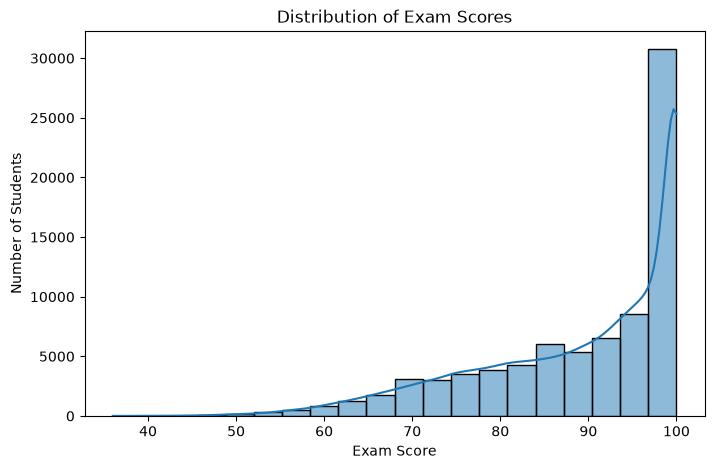

In [28]:
plt.figure(figsize=(8,5))

sns.histplot(df['exam_score'], bins=20, kde=True)

plt.title('Distribution of Exam Scores')
plt.xlabel('Exam Score')
plt.ylabel('Number of Students')

plt.show()

## interpretation
- The exam scores are mostly concentrated in the higher range.
- A large number of students scored between approximately 95 and 100,
- while relatively fewer students scored below 70.
- The distribution is left-skewed, indicating that most students performed well in the exam, with fewer      -
- students having lower scores.

## Exam score statistics

- What are the average, minimum, and maximum exam scores?

In [29]:
#df['exam_score'].mean()
#df["exam_score"].max()
df["exam_score"].min()

np.int64(36)

### interpretation
- The average exam score is 89.14135,which is overall performance of the students.
- The maximum exam score is 100,which is the highest score in the dataset.
- The minimum exam score is 36 ,which is the lowest score in the dataset.

## Study Hours
- How many hours do students study per day?

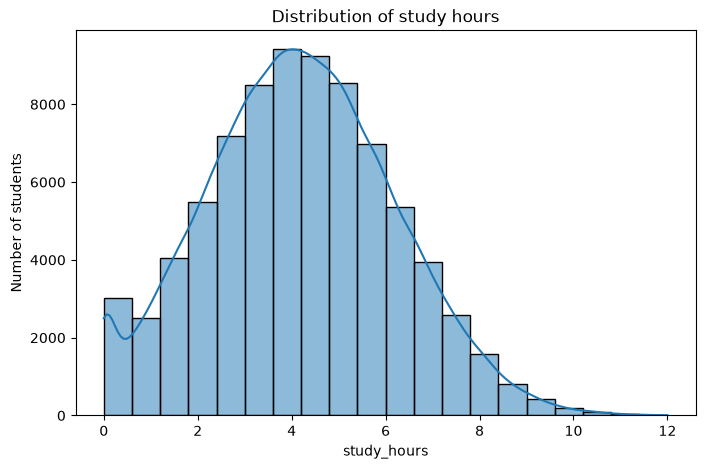

In [30]:
plt.figure(figsize=(8,5))
sns.histplot(df["study_hours_per_day"],bins=20,kde=True)
plt.title("Distribution of study hours")
plt.xlabel("study_hours")
plt.ylabel("Number of students")
plt.show()

## interpretation
- The histogram shows how many hours students study per day.
Most students study around the middle range, while fewer students
study very little or very much.

## Stress
- What is the distribution of students' stress levels?

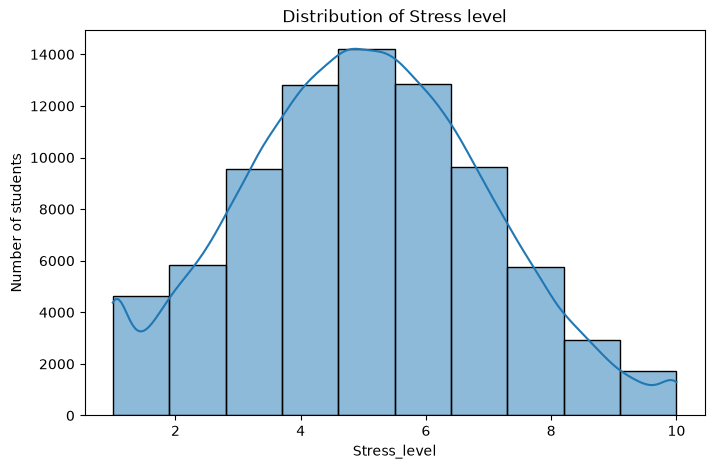

In [31]:
plt.figure(figsize=(8,5))
sns.histplot(df["stress_level"],bins=10,kde=True)
plt.title("Distribution of Stress level")
plt.xlabel("Stress_level")
plt.ylabel("Number of students")
plt.show()

## Interpretation
- The histogram shows the stress levels of the students.
Most students have stress levels around the middle range,
while fewer students have very low or very high stress levels.

## Motivation
- How are students distributed across motivation levels?

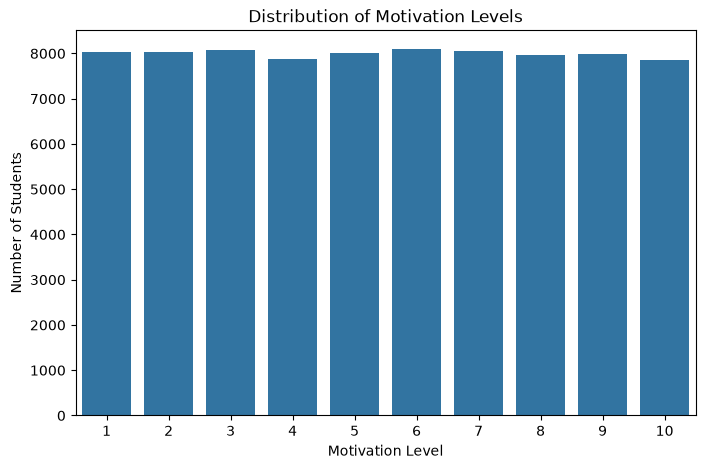

In [32]:
plt.figure(figsize=(8,5))

sns.countplot(x='motivation_level', data=df)

plt.title('Distribution of Motivation Levels')
plt.xlabel('Motivation Level')
plt.ylabel('Number of Students')

plt.show()

## Interpretation
- The graph shows the number of students at different motivation levels. It helps us understand which motivation levels are more common among the students.

## Bivariate Analysis
- study relationship between two variables.

### study Hours vs  Exam score
- Does study time relate to exam performance?

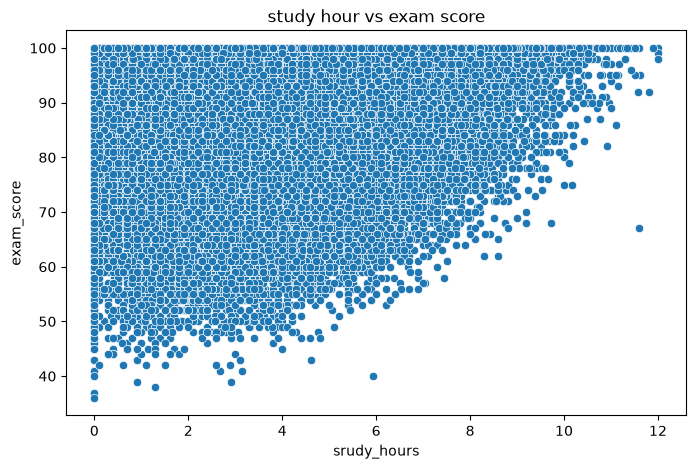

In [33]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    x="study_hours_per_day",
    y="exam_score",
    data=df
)
plt.title("study hour vs exam score")
plt.xlabel("srudy_hours")
plt.ylabel("exam_score")
plt.show()

## Insight

- Students who study more hours generally tend to have higher exam scores.
- This shows a positive relationship between study hours and exam scores.
- However, this relationship does not prove that studying more directly causes higher scores.


## Attendance vs Exam score

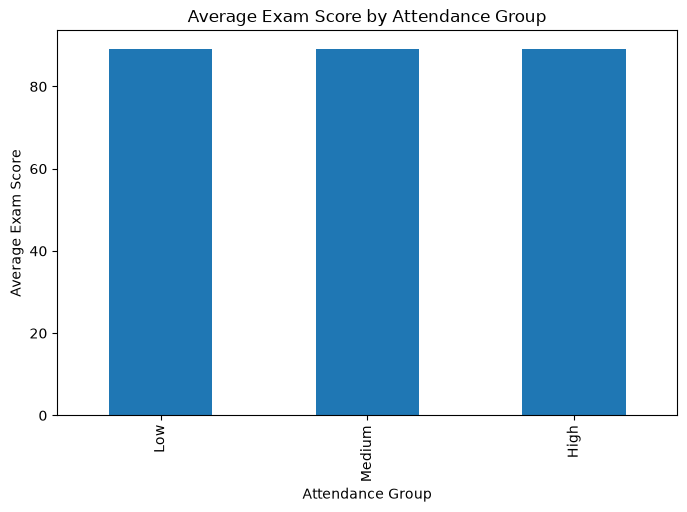

In [34]:
attendance_scores = df.groupby(
    "attendance_group"
)["exam_score"].mean()

attendance_scores.plot(kind="bar", figsize=(8,5))

plt.title("Average Exam Score by Attendance Group")
plt.xlabel("Attendance Group")
plt.ylabel("Average Exam Score")
plt.show()

## Insight
- The average exam scores are compared across different attendance groups.
- The differences between the groups are relatively small.
- Therefore, this dataset does not show a strong relationship between attendance percentage and exam score.

## Previous GPA vs Exam Score
- Is previous GPA associated with current exam score?

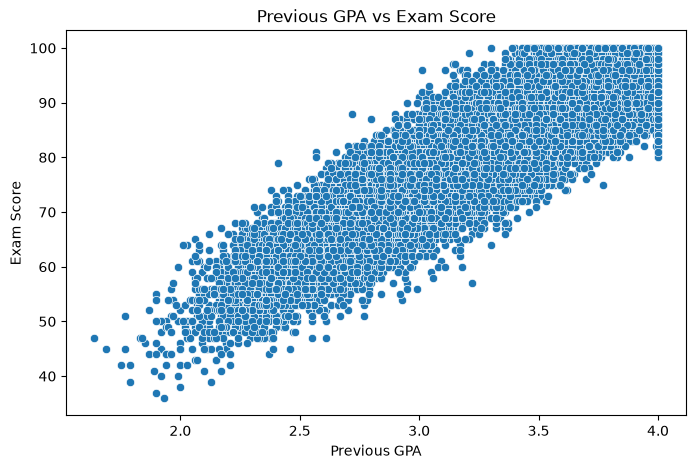

In [35]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    x='previous_gpa',
    y='exam_score',
    data=df
)

plt.title('Previous GPA vs Exam Score')
plt.xlabel('Previous GPA')
plt.ylabel('Exam Score')

plt.show()

## Interpretation
- Students with higher previous GPA generally have higher exam scores.
- Previous GPA has a strong positive relationship with exam score.
- This is an association and does not prove causation.


## Sleep vs Exam Score
- What pattern is visible between sleep hours and exam score?


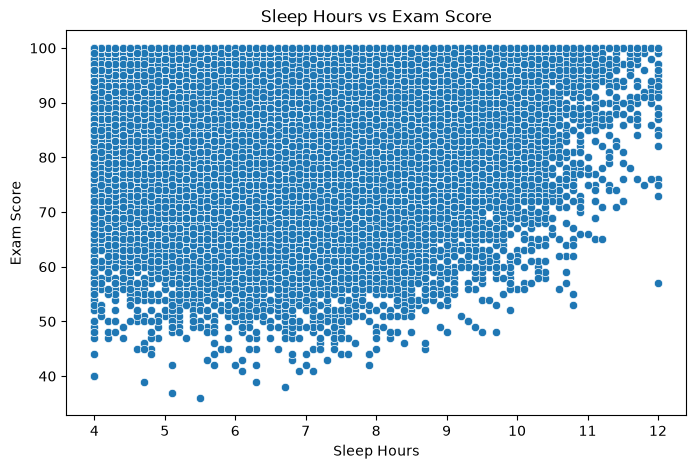

In [36]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    x='sleep_hours',
    y='exam_score',
    data=df
)

plt.title('Sleep Hours vs Exam Score')
plt.xlabel('Sleep Hours')
plt.ylabel('Exam Score')

plt.show()

## Insight

- Students with adequate sleep tend to perform better in examinations compared to students with insufficient sleep.

## Stress vs Exam Score
- Is stress level associated with exam performance?

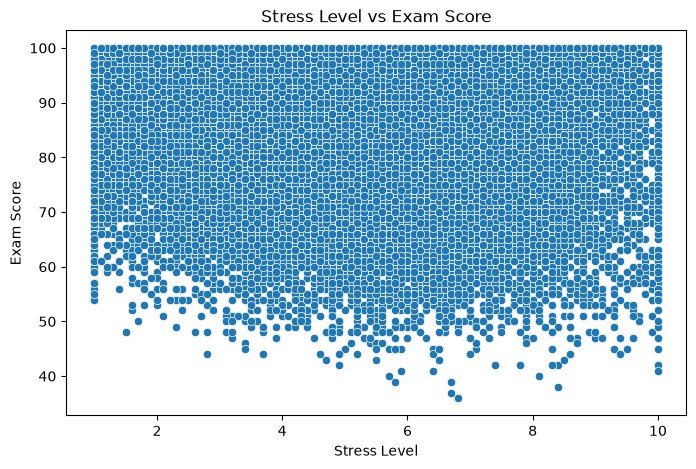

In [37]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    x='stress_level',
    y='exam_score',
    data=df
)

plt.title('Stress Level vs Exam Score')
plt.xlabel('Stress Level')
plt.ylabel('Exam Score')

plt.show()

## Interpretation
- Stress level has a weak negative relationship with exam score.
- As stress level increases, exam scores tend to decrease slightly.
- The relationship is weak, so stress level alone does not strongly explain exam performance.

### Exam Anxiety vs Exam Score
- Is exam anxiety associated with exam performance?


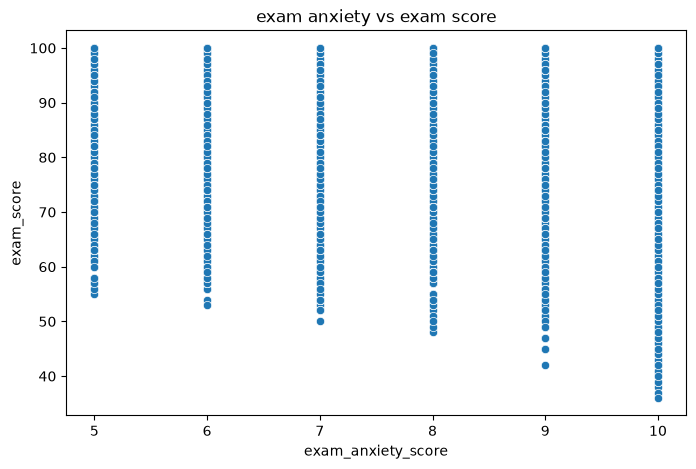

In [38]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    x="exam_anxiety_score",
    y="exam_score",
    data=df
)
plt.title("exam anxiety vs exam score")
plt.xlabel("exam_anxiety_score")
plt.ylabel("exam_score")
plt.show()


## Interpretation
- Exam anxiety has a negative relationship with exam score.
- Students with higher exam anxiety tend to have lower exam scores.
- The relationship is stronger than the relationship between stress level and exam score, but it is still not proof of causation.

## Correlation Analysis


#### correlation matrix
- Which numerical variables are related to each other?

In [39]:
numeric_df=df.select_dtypes(include=np.number)
correlation=numeric_df.corr()
correlation

,student_id,age,study_hours_per_day,social_media_hours,netflix_hours,attendance_percentage,sleep_hours,exercise_frequency,mental_health_rating,previous_gpa,semester,stress_level,social_activity,screen_time,parental_support_level,motivation_level,exam_anxiety_score,time_management_score,exam_score,study_efficiency
student_id,1.000000,0.002050,0.002472,-0.003556,-0.006812,0.002696,-0.001518,-0.001599,0.003681,0.007096,0.000103,-0.000775,-0.008451,-0.003746,-0.000397,0.004605,-0.004330,-0.000304,0.007557,0.001093
age,0.002050,1.000000,-0.001308,-0.005747,-0.003948,0.000158,0.006555,-0.000712,-0.002754,0.000487,-0.001653,0.001166,0.000028,-0.004347,0.001003,-0.000795,0.000140,0.002203,0.000487,0.001147
study_hours_per_day,0.002472,-0.001308,1.000000,-0.001322,-0.004699,0.004509,-0.000348,0.003093,-0.000224,0.257445,0.004194,-0.002981,-0.003822,0.717972,-0.001055,0.000812,-0.001437,0.001461,0.241460,-0.190641
social_media_hours,-0.003556,-0.005747,-0.001322,1.000000,-0.006302,0.003496,-0.003602,-0.005077,0.000555,-0.007078,0.000105,0.003336,-0.002281,0.516475,-0.004291,0.000105,0.001991,0.003953,-0.006351,0.006742
netflix_hours,-0.006812,-0.003948,-0.004699,-0.006302,1.000000,-0.000227,0.004260,-0.007706,0.003952,-0.002506,0.004142,0.001126,-0.001113,0.409792,0.000649,-0.004237,0.003392,0.005354,-0.001271,-0.000478
attendance_percentage,0.002696,0.000158,0.004509,0.003496,-0.000227,1.000000,0.001027,-0.001085,-0.000908,0.002926,0.001991,-0.003385,0.002735,0.004889,-0.001279,0.001223,-0.000283,-0.003417,0.002876,-0.001334
sleep_hours,-0.001518,0.006555,-0.000348,-0.003602,0.004260,0.001027,1.000000,0.003268,0.007061,0.097282,0.005823,-0.000656,-0.002975,-0.000742,0.000911,0.000508,-0.000500,0.000685,0.090820,0.000802
exercise_frequency,-0.001599,-0.000712,0.003093,-0.005077,-0.007706,-0.001085,0.003268,1.000000,-0.004744,0.092738,-0.000583,0.005689,0.000055,-0.003220,0.002438,0.007927,-0.006036,0.002229,0.086983,0.000858
mental_health_rating,0.003681,-0.002754,-0.000224,0.000555,0.003952,-0.000908,0.007061,-0.004744,1.000000,0.011431,0.001600,-0.116863,0.000594,0.002128,-0.002222,-0.001888,0.001211,-0.003228,0.010556,0.001548
previous_gpa,0.007096,0.000487,0.257445,-0.007078,-0.002506,0.002926,0.097282,0.092738,0.011431,1.000000,0.000558,-0.127729,-0.002079,0.180460,-0.006603,0.270758,-0.255692,0.007474,0.932940,-0.015324


## Correlation Heatmap
- Which numerical variables have stronger positive or negative correlations?

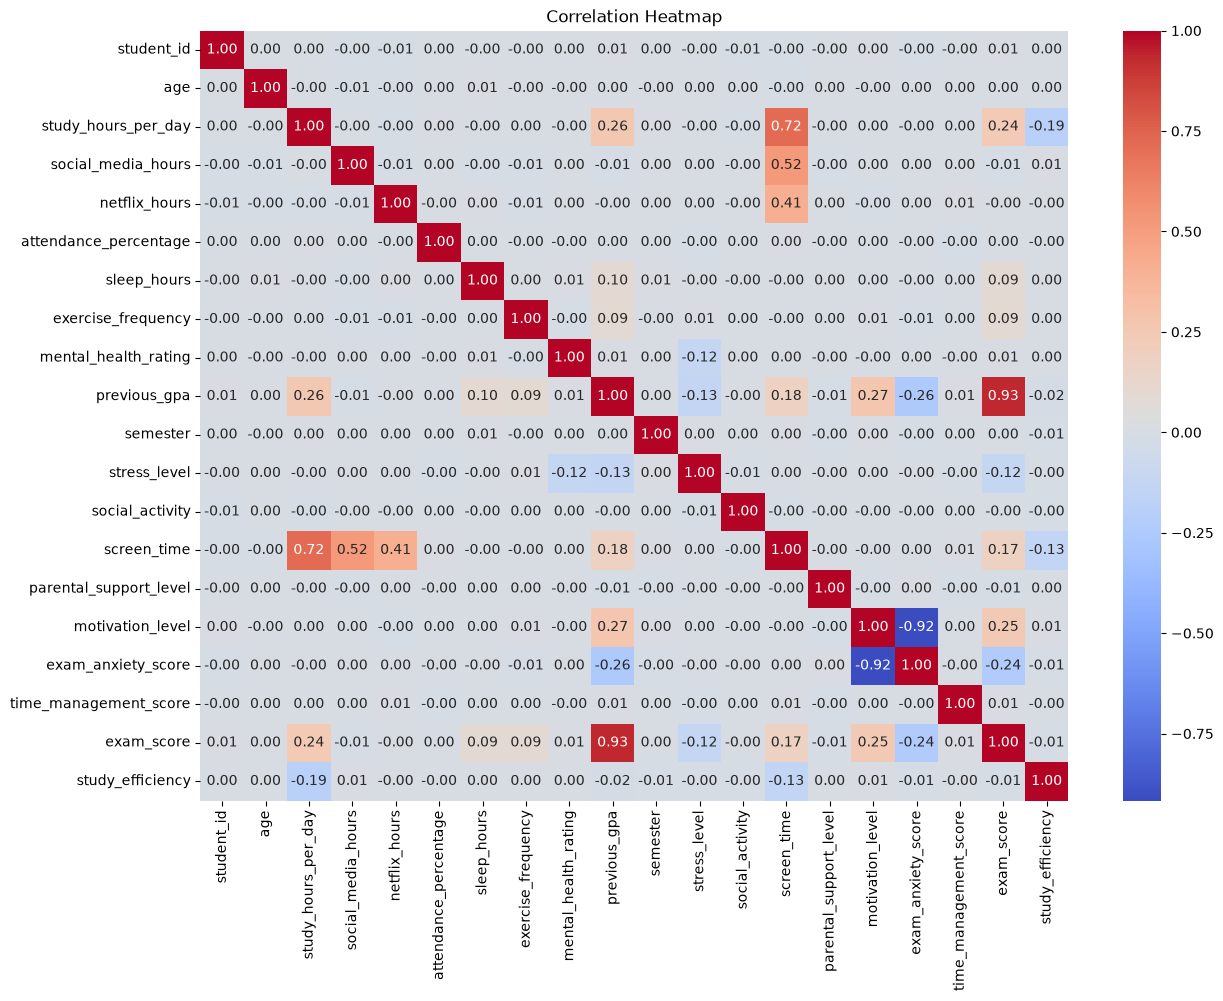

In [40]:
plt.figure(figsize=(14,10))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.show()

## Observation

The heatmap shows the relationship between numerical variables.

- Positive correlation means both variables increase together.
- Negative correlation means one variable increases while the other decreases.
- Values close to 1 or -1 indicate a strong relationship.
- Values close to 0 indicate a weak relationship.

## Correlation With Exam Score
- Which numerical variables have the strongest correlation with exam score?

In [41]:
exam_corr=correlation["exam_score"].sort_values(ascending=False)
exam_corr

exam_score                1.000000
previous_gpa              0.932940
motivation_level          0.250287
study_hours_per_day       0.241460
screen_time               0.169788
sleep_hours               0.090820
exercise_frequency        0.086983
mental_health_rating      0.010556
student_id                0.007557
time_management_score     0.005940
attendance_percentage     0.002876
semester                  0.000541
age                       0.000487
netflix_hours            -0.001271
social_activity          -0.002795
parental_support_level   -0.006333
social_media_hours       -0.006351
study_efficiency         -0.010647
stress_level             -0.118550
exam_anxiety_score       -0.235909
Name: exam_score, dtype: float64

### interpretation
- This analysis shows the correlation of different numerical variables with exam score.

- The values are arranged from highest to lowest correlation.
A positive value means the variables generally increase together,
while a negative value means they move in opposite directions.

- This helps us identify which numerical variables have stronger
relationships with exam performance.

- Correlation shows association, not causation.

## Group Analysis
- Now we compare different groups.

## Motivation vs Exam Score
- Do average exam scores differ across motivation levels?

In [42]:
motivation_scores = df.groupby(
    'motivation_level'
)['exam_score'].mean()

motivation_scores

motivation_level
1     84.923585
2     85.756034
3     86.534365
4     87.425583
5     88.211906
6     89.579980
7     90.615947
8     91.747077
9     93.030421
10    93.704010
Name: exam_score, dtype: float64

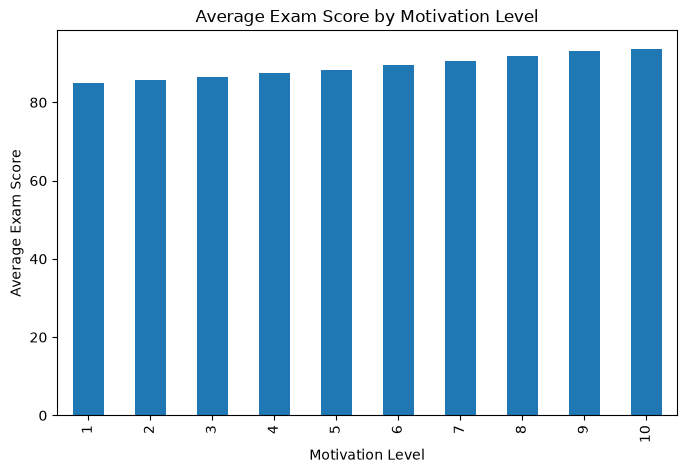

In [43]:
motivation_scores.plot(
    kind='bar',
    figsize=(8,5)
)

plt.title('Average Exam Score by Motivation Level')
plt.xlabel('Motivation Level')
plt.ylabel('Average Exam Score')

plt.show()

## Interpretation 
- Average exam scores generally increase as motivation level increases.
- Students with higher motivation levels have higher average exam scores in this dataset.
- This shows a positive association between motivation and exam performance.

### Study Environment vs Exam score
- Do average exam scores differ across study environments?

In [44]:
environment_scores=df.groupby("study_environment")["exam_score"].mean()
environment_scores

study_environment
Cafe                 88.610675
Co-Learning Group    90.175560
Dorm                 85.628141
Library              90.070867
Quiet Room           91.259021
Name: exam_score, dtype: float64

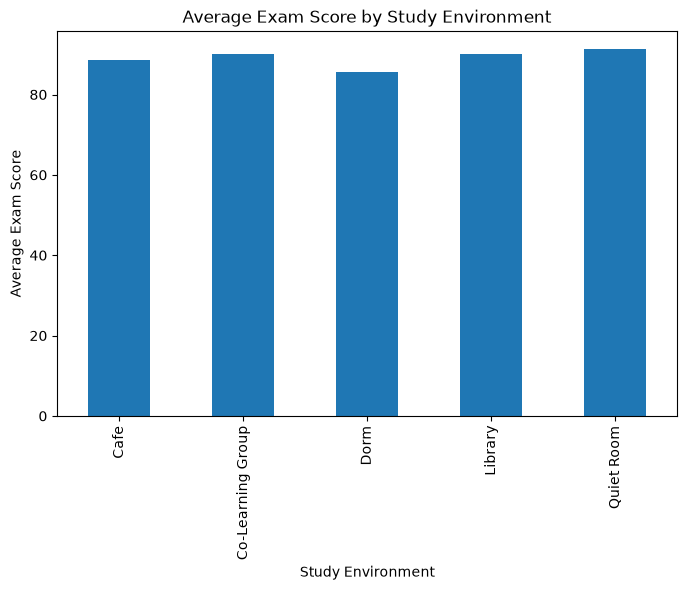

In [45]:
environment_scores.plot(
    kind="bar",
    figsize=(8,5)
)

plt.title('Average Exam Score by Study Environment')
plt.xlabel('Study Environment')
plt.ylabel('Average Exam Score')

plt.show()

## interpretation
- Average exam scores differ across study environments.
- Students studying in the Quiet Room have the highest average score, while students in the Dorm have the lowest average score.
- This shows differences between study-environment groups, but it does not prove that the environment causes higher or lower scores.

## Tutoring Access vs Exam score
- Do students with tutoring access have different average exam scores?

In [46]:
tutoring_scores = df.groupby(
    'access_to_tutoring'
)['exam_score'].mean()

tutoring_scores

access_to_tutoring
No     87.747122
Yes    90.538300
Name: exam_score, dtype: float64

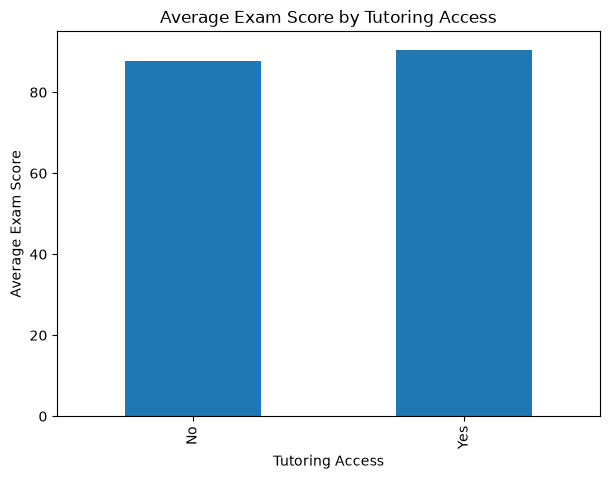

In [47]:
tutoring_scores.plot(
    kind='bar',
    figsize=(7,5)
)

plt.title('Average Exam Score by Tutoring Access')
plt.xlabel('Tutoring Access')
plt.ylabel('Average Exam Score')

plt.show()

## Insight

- Students with access to tutoring have a higher average exam score than students without tutoring.
- The difference in average scores is about 2.79 points.
- This shows an association and does not prove that tutoring caused the higher scores.

## Drop risk vs Exam Score
- How does exam performance differ between dropout-risk groups?

In [48]:
dropout_scores = df.groupby(
    'dropout_risk'
)['exam_score'].mean()

dropout_scores

dropout_risk
No     89.286745
Yes    81.934260
Name: exam_score, dtype: float64

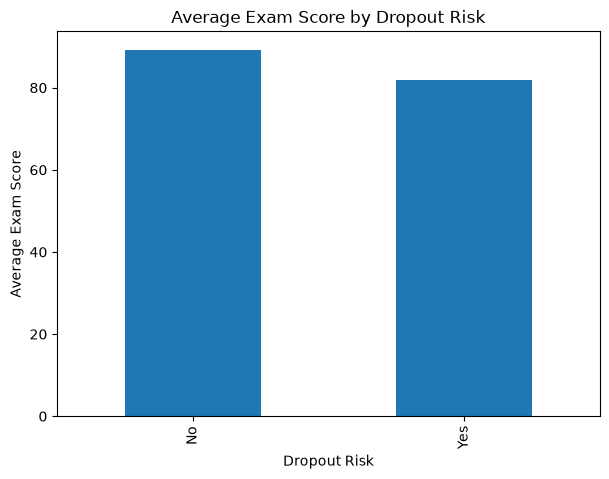

In [49]:
dropout_scores.plot(
    kind='bar',
    figsize=(7,5)
)

plt.title('Average Exam Score by Dropout Risk')
plt.xlabel('Dropout Risk')
plt.ylabel('Average Exam Score')

plt.show()

## interpretation
- Students classified as having no dropout risk have a higher average exam score than students classified as having dropout risk.
- The average scores are about 89.29 and 81.93 respectively.
- This shows an association between dropout-risk classification and exam performance.

## Major vs Exam score
- Do average exam scores differ across majors?

In [50]:
major_score=df.groupby("major")['exam_score'].mean()
major_score

major
Arts                88.825990
Biology             88.850163
Business            88.959476
Computer Science    90.271794
Engineering         89.099478
Psychology          88.842003
Name: exam_score, dtype: float64

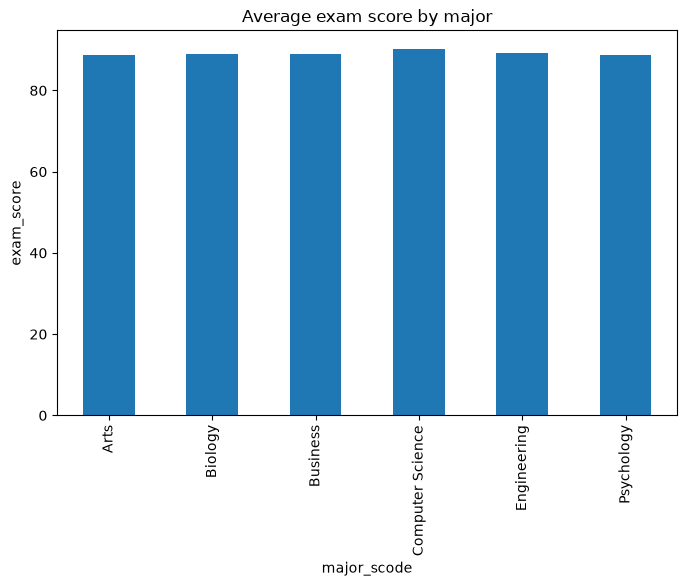

In [51]:
major_score.plot(
 kind="bar",
 figsize=(8,5)   
)
plt.title("Average exam score by major")
plt.ylabel("exam_score")
plt.xlabel("major_scode")
plt.show()

## Interpretation
- Average exam scores are fairly similar across the different majors.
- Computer Science has the highest average score at about 90.27.
- The differences between majors are relatively small.
- Therefore, the dataset does not show a large difference in exam performance across majors.

## Semester vs exam score
- Do average exam scores differ across semesters?

In [52]:
semester_score=df.groupby('semester')['exam_score'].mean()
semester_score

semester
1    89.104423
2    89.068600
3    89.103396
4    89.227604
5    89.276880
6    89.123271
7    89.199705
8    89.025649
Name: exam_score, dtype: float64

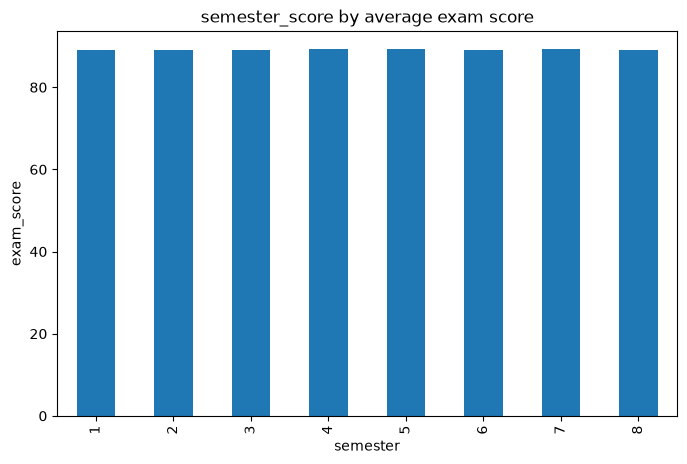

In [53]:
semester_score.plot(
    kind='bar',
    figsize=(8,5)
)
plt.title("semester_score by average exam score")
plt.xlabel("semester")
plt.ylabel("exam_score")
plt.show()

## Interpretation
- Average exam scores are very similar across all semesters.
- The difference between the highest and lowest semester averages is very small.
- Therefore, semester does not show a meaningful difference in average exam score in this dataset.

## Gender vs exam score
- Do average exam scores differ across gender groups?

In [54]:
gender_scores = df.groupby(
    'gender'
)['exam_score'].mean()

gender_scores

gender
Female    89.108444
Male      89.152034
Other     89.163665
Name: exam_score, dtype: float64

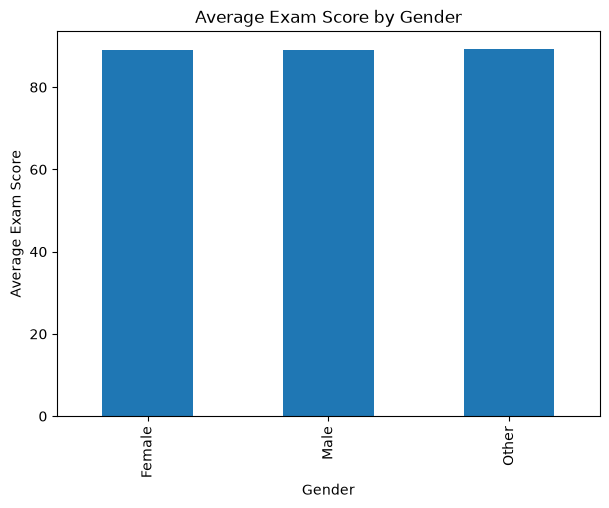

In [55]:
gender_scores.plot(
    kind='bar',
    figsize=(7,5)
)

plt.title('Average Exam Score by Gender')
plt.xlabel('Gender')
plt.ylabel('Average Exam Score')

plt.show()

## Interpretation
- Average exam scores are very similar across the gender groups.
- The differences between the groups are very small.
- Therefore, this dataset does not show a meaningful difference in average exam scores across gender groups.

### Exploratory Risk Profile
- Dropout risk = Yes
- Stress ≥ 7
- Exam anxiety ≥ 7
- Motivation ≤ 4

- How many students satisfy all four exploratory risk conditions?

In [56]:
risk_profile = df[
    (df['dropout_risk'] == 'Yes') &
    (df['stress_level'] >= 7) &
    (df['exam_anxiety_score'] >= 7) &
    (df['motivation_level'] <= 4)
]

print("Number of students:", len(risk_profile))

Number of students: 1582


In [57]:
risk_profile.head()

,student_id,age,gender,major,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,...,exam_anxiety_score,learning_style,time_management_score,exam_score,attendance_group,sleep_catagory,study_efficiency,performance_category,screen_time_category,stress_category
24,100024,16,Other,Psychology,6.100000,1.3,1.5,Yes,86.7,5.2,...,10,Kinesthetic,9.4,80,High,Low sleep,13.114754,High,Low,High
50,100050,27,Female,Psychology,7.300000,2.1,3.7,No,76.0,8.4,...,10,Visual,6.9,79,Medium,Normal sleep,10.821918,High,Low,High
118,100118,16,Other,Business,8.000000,4.8,2.0,Yes,78.3,7.6,...,10,Kinesthetic,4.5,93,Medium,Normal sleep,11.625000,High,Medium,High
157,100157,21,Other,Biology,2.500000,0.7,3.3,No,40.7,9.1,...,10,Reading,1.7,60,Low,High sleep,24.000000,Average,Low,High
239,100239,24,Other,Computer Science,6.978527,2.3,2.1,No,65.3,7.3,...,10,Reading,7.3,100,Medium,Normal sleep,14.329671,High,Low,High


## Key insights


1. Previous GPA: Students with higher previous GPA usually get higher exam marks.
2. Study Hours: Students who study more hours usually get higher exam marks.
3. Motivation: Students with higher motivation usually get better exam marks.
4. Exam Anxiety: Students with higher exam anxiety usually get lower exam marks.
5. Stress: Higher stress is linked with slightly lower exam marks.
6. Tutoring: Students who have tutoring usually have higher average exam marks.
7. Study Environment: Exam marks are different in different study environments. The Quiet Room has the       
highest average score in this dataset.
8. Attendance and Social Media: Attendance and social media usage do not show a clear relationship with exam marks in this dataset.

.

## Conclusion
- In this project, I analyzed student habits and their relationship with exam performance. The analysis shows that previous GPA, study hours, and motivation have a positive relationship with exam scores. Exam anxiety and stress have a negative relationship with exam scores. Students with tutoring also have higher average exam scores.

- Overall, the analysis shows that previous academic performance, study habits, motivation, and exam anxiety are important factors to consider when understanding student exam performance. However, these relationships do not prove that one factor directly causes higher or lower exam scores.

## Recommendations
- Study consistently and manage study time properly.
- Maintain good study habits and review lessons regularly.
- Stay motivated and set clear academic goals.
- Manage exam anxiety and stress through proper planning and relaxation.
- Get sufficient and regular sleep.
- Seek tutoring or academic support when needed.
- Use social media responsibly and avoid unnecessary distractions.